# Learning the MION-to-BOLD transform with mixed signals

The [proof-of-principle notebook](learn_hrf_transform_proof_of_principle.ipynb) shows that a convolutional kernel can map a MION time series onto BOLD in the simplest case: one neural signal, no noise. Here voxels mix signals that are shared between species with signals that are specific to one species or one subject. The kernel is learned with multiview temporal alignment (MVTA), which compares the species in a shared space learned from the data, and is compared with three alternatives.

Both species watch the same movie, one measured with BOLD and one with MION. Each method is evaluated by **cross-species stimulus epoch decoding (SED)**: take a 10-TR window of the movie in one subject and find the matching window in the other species' data. Every MION subject is decoded against the BOLD subjects and every BOLD subject against the MION subjects. A 200-TR run has 191 windows. Windows that overlap the correct one are not candidates, which leaves about 173, so chance is about 1 in 173. The figures show accuracy above chance.

Four ways of temporally preparing the data are compared. All four are decoded the same way, so any difference comes from the temporal preparation.

In [1]:
%matplotlib inline
from mvta import (
    bold_hrf, decode_methods, learn_kernels, mion_hrf,
    plot_decoding, plot_neural, plot_sed_methods, simulate_movie,
)
import numpy as np

tr = 2.5
duration = 32.0
kernel_seconds = 15.0  # learned kernel duration, in seconds. Must be a multiple of tr.
kernel_length = int(round(kernel_seconds / tr))
if abs(kernel_seconds - kernel_length * tr) > 1e-6:
    raise ValueError(f"kernel_seconds ({kernel_seconds}) must be a multiple of tr ({tr}).")
seed = 42
win_size = 10  # SED window, in TRs
kernel_n_components = 2  # SRM rank for kernel learning; chosen from {2, 5, 10, 20} on mixed-signals
sed_n_components = 10  # dimensionality of the SED SRM shared space
filter_shared = True  # rotate and weight SED components by their cross-species agreement

## The simulated movie

Each run contains three kinds of neural signal, which are mixed into voxels, convolved with that species' HRF, and z-scored:

- `n_shared` signals are the movie, identical in both species.
- `n_group` signals are shared by the subjects of one species and differ between species.
- `n_idio` signals are private to each subject.

Each voxel mixes `n_signals_per_voxel` of these signals, and the mixture stays the same across runs, as a real voxel keeps its tuning. Each signal is a normalized average spike rate: an independent Uniform(0, 1) draw at every TR.

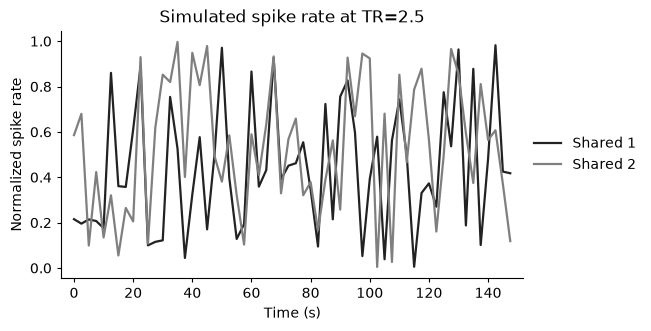

In [2]:
n_shared = 2
n_group = 2
n_idio = 2
n_subjects = 2  # per species
n_signals_per_voxel = 3
n_tr = 200
n_runs = 5
n_voxels = 50  # per subject
maxiter = 100  # BFGS iteration limit; both learned methods converge well before it

bold = bold_hrf(tr=tr, time_length=duration)
mion = mion_hrf(tr=tr, time_length=duration)
simulation = simulate_movie(
    bold, mion,
    n_tr=n_tr, tr=tr, n_runs=n_runs, n_subjects=n_subjects, n_voxels=n_voxels,
    n_shared=n_shared, n_group=n_group, n_idio=n_idio,
    n_signals_per_voxel=n_signals_per_voxel, rng=seed,
)
fig = plot_neural(simulation.neural, simulation.run_index, tr)

## Four ways to prepare the data

| Method | Temporal preparation | Shared space |
|---|---|---|
| **Double convolution** | convolve MION with the BOLD HRF and BOLD with the MION HRF, using the HRFs that generated the data | fit on the training runs |
| **MVTA** | convolve MION with a kernel learned by minimizing between-species disparity *in an SRM shared space, rotated and weighted toward BOLD–MION correlation* | fit on the training runs |
| **No multiview** | convolve MION with a kernel learned by minimizing disparity between *voxel averages*, without a shared space | fit on the training runs |
| **No alignment** | leave MION and BOLD unchanged | fit on the training runs |

Every method then goes through the same decoding step. Only double convolution prepares both species; the learned methods prepare MION only, and no alignment prepares neither.

## Learn the kernels

One kernel is learned per held-out run for each of the two learned methods (MVTA and no multiview). A kernel never sees the run it is later tested on.

As in the proof-of-principle notebook, each kernel is learned with BFGS, starting from a flat kernel whose weights sum to one. Only the loss differs. MVTA fits an SRM shared space to the BOLD and transformed MION subjects for every candidate kernel, rotates and weights the scores toward BOLD–MION correlation, and measures the between-species disparity there. `kernel_n_components` sets that SRM rank. No multiview measures disparity between each subject's voxel average. A fold prints a message only if BFGS stops at `maxiter` before converging.

In [3]:
common = dict(
    kernel_length=kernel_length,
    n_components=kernel_n_components,
    bold_hrf=bold, mion_hrf=mion, maxiter=maxiter,
)
print("MVTA")
mvta_kernels = learn_kernels(
    simulation.bold, simulation.mion, simulation.run_index,
    objective="multiview", verbose=True, **common,
)
print("No multiview")
voxel_average_kernels = learn_kernels(
    simulation.bold, simulation.mion, simulation.run_index,
    objective="voxel_average", verbose=True, **common,
)

MVTA
Fold 1/5: holding out run 0


Fold 2/5: holding out run 1


Fold 3/5: holding out run 2


Fold 4/5: holding out run 3


Fold 5/5: holding out run 4


No multiview
Fold 1/5: holding out run 0


Fold 2/5: holding out run 1


Fold 3/5: holding out run 2


Fold 4/5: holding out run 3


Fold 5/5: holding out run 4


## Decode

For each held-out run:

1. Apply that method's temporal preparation. Double convolution convolves observed MION with the BOLD HRF and observed BOLD with the MION HRF. The learned methods convolve MION only, and no alignment leaves both species unchanged.
2. Fit the SED shared space on the other runs, using the prepared BOLD and MION subjects together. This is SRM with `sed_n_components` components, separate from the SRM used to learn the kernels. It can have more components than there are shared signals, so some components carry signal that is not shared between species.
3. With `filter_shared`, rotate the shared space toward the directions where BOLD and MION agree, and weight each direction by how far that agreement exceeds chance:
   - One training run is set aside as a calibration run, and SRM is fit on the remaining training runs. The calibration run is projected into that space, and the BOLD–MION correlation matrix of its components is decomposed into paired BOLD and MION directions, ordered by how strongly they correlate.
   - Chance is estimated by circularly shifting the MION series in time, which breaks the alignment between species while keeping each series' temporal structure. A direction keeps a positive weight only if its correlation exceeds the 95th percentile of the strongest correlation found across 20 such shifts.
   - The filter is estimated on the calibration run rather than on the runs SRM was fit to, because SRM's fit inflates the correlations on its own training data. Each training run takes a turn as the calibration run.
4. Project the held-out run into the shared space (rotated and weighted, with the filter).
5. Decode in both directions. For every 10-TR window in a MION subject, find the window in the mean BOLD time course with the highest correlation; likewise, match every BOLD subject's windows against the mean MION time course. Windows that overlap the correct window are excluded, apart from the correct window itself. With the filter, the window correlations are averaged over calibration runs before the best match is chosen. The match counts when it picks the same time.

Accuracy is the fraction of correct matches minus chance. It is averaged over subjects within each direction, and then over the two directions, so neither species dominates when the groups differ in size. The printout reports how many directions passed the null; the simulation has `n_shared` shared signals, so it should be close to that.

In [4]:
results = decode_methods(
    simulation.bold, simulation.mion, simulation.run_index,
    {
        "double convolution": bold,
        "MVTA": mvta_kernels,
        "no multiview": voxel_average_kernels,
        "no alignment": np.array([1.0]),
    },
    bold_kernels={"double convolution": mion},
    n_components=sed_n_components, win_size=win_size,
    filter_shared=filter_shared, random_state=seed,
)
for label, values in results.items():
    print(f"{label:20s} mean {values.mean():.3f}   runs {np.round(values, 3)}")

SED spatial alignment: SRM, 10 components, with the cross-species filter


Directions above the time-shift null (mean over calibration runs)


  double convolution   1.9 of 10


  MVTA                 2.0 of 10


  no multiview         1.9 of 10


  no alignment         1.6 of 10


double convolution   mean 0.669   runs [0.604 0.709 0.598 0.719 0.714]
MVTA                 mean 0.892   runs [0.924 0.901 0.84  0.888 0.907]
no multiview         mean 0.312   runs [0.232 0.427 0.282 0.338 0.28 ]
no alignment         mean 0.014   runs [0.024 0.015 0.019 0.003 0.006]


## Figure

Bars show the mean across held-out runs and dots show each run. The two learned methods share the kernel length, optimizer, and decoding step; they differ only in the loss used to learn the kernel.

MVTA decodes almost perfectly. No multiview learns its kernel from voxel averages, which mix shared, species-specific, and subject-specific signal, so the kernel partly fits signal that is not shared between species.

Double convolution trails MVTA even though it uses the HRFs that generated the data. The likely reason is that convolving each species with the other's HRF passes both through two slow responses, which smooths away fast changes that make one movie window distinct from another. MVTA's kernel instead maps MION onto BOLD, so each species is smoothed by only one response.

Double convolution is also artificially privileged here: in real brains the HRF varies across regions and individuals, so double convolution with canonical HRFs can compound mis-modeling.

No alignment confounds response timing with the measurement method. A region whose neural response comes later, measured with MION's early-peaking response, can look like a region with an earlier neural response measured with BOLD.

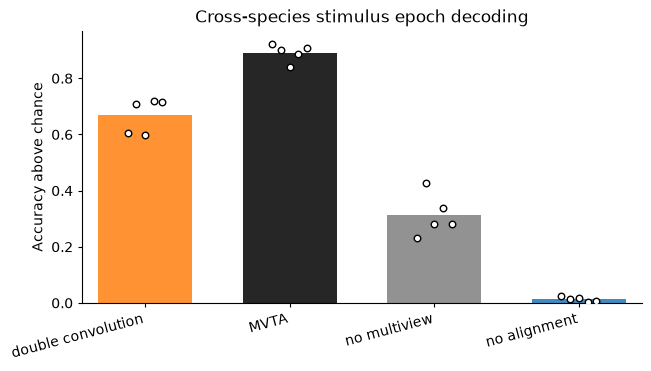

In [5]:
fig = plot_decoding(results, title="Cross-species stimulus epoch decoding")

## Robustness across signal compositions

The final comparison keeps the decoding step fixed (`sed_n_components`, `filter_shared`, and `win_size` from the settings cell) and changes only the balance of shared, group-specific, and idiosyncratic signals.

The four clusters are balanced `(2, 2, 2)`, shared-rich `(4, 1, 1)`, group-specific dominant `(1, 4, 1)`, and idiosyncratic dominant `(1, 1, 4)`. Each dot is the mean across held-out runs for one simulation seed; bars average the seeds.

MVTA's advantage over no multiview is smallest in the shared-rich condition. When most of each voxel's signal is shared, the voxel average is already a good target for the kernel. When most of the signal is species-specific or subject-specific, the voxel average is dominated by signal the other species does not have, and only the shared space isolates what the kernel should align.

In [ ]:
condition_specs = [
    ("Balanced\n(2, 2, 2)", 2, 2, 2),
    ("Shared-rich\n(4, 1, 1)", 4, 1, 1),
    ("Group-specific\ndominant\n(1, 4, 1)", 1, 4, 1),
    ("Idiosyncratic\ndominant\n(1, 1, 4)", 1, 1, 4),
]
robustness_seeds = [seed, 7, 19]
method_labels = ["double convolution", "MVTA", "no multiview", "no alignment"]
robustness_results = {
    label: {method: [] for method in method_labels}
    for label, *_ in condition_specs
}

for condition_label, condition_shared, condition_group, condition_idio in condition_specs:
    for condition_seed in robustness_seeds:
        printable_label = condition_label.replace("\n", " ")
        print(f"Robustness condition: {printable_label}, seed {condition_seed}", flush=True)
        is_cached_default = (
            condition_seed == seed
            and (condition_shared, condition_group, condition_idio)
            == (n_shared, n_group, n_idio)
        )
        if is_cached_default:
            condition_simulation = simulation
            condition_mvta_kernels = mvta_kernels
            condition_voxel_average_kernels = voxel_average_kernels
        else:
            condition_simulation = simulate_movie(
                bold, mion,
                n_tr=n_tr, tr=tr, n_runs=n_runs, n_subjects=n_subjects,
                n_voxels=n_voxels, n_shared=condition_shared,
                n_group=condition_group, n_idio=condition_idio,
                n_signals_per_voxel=n_signals_per_voxel, rng=condition_seed,
            )
            condition_common = dict(
                kernel_length=kernel_length, n_components=kernel_n_components,
                bold_hrf=bold, mion_hrf=mion, maxiter=maxiter,
            )
            condition_mvta_kernels = learn_kernels(
                condition_simulation.bold, condition_simulation.mion,
                condition_simulation.run_index,
                objective="multiview", **condition_common,
            )
            condition_voxel_average_kernels = learn_kernels(
                condition_simulation.bold, condition_simulation.mion,
                condition_simulation.run_index,
                objective="voxel_average", **condition_common,
            )

        condition_kernels = {
            "double convolution": bold,
            "MVTA": condition_mvta_kernels,
            "no multiview": condition_voxel_average_kernels,
            "no alignment": np.array([1.0]),
        }
        condition_scores = decode_methods(
            condition_simulation.bold, condition_simulation.mion,
            condition_simulation.run_index, condition_kernels,
            bold_kernels={"double convolution": mion},
            n_components=sed_n_components, win_size=win_size,
            filter_shared=filter_shared, random_state=condition_seed, verbose=False,
        )
        for preparation, values in condition_scores.items():
            robustness_results[condition_label][preparation].append(values.mean())

robustness_results = {
    condition_label: {
        method: np.asarray(values)
        for method, values in methods.items()
    }
    for condition_label, methods in robustness_results.items()
}
for condition_label, methods in robustness_results.items():
    advantage = methods["MVTA"].mean() - methods["no multiview"].mean()
    printable_label = condition_label.replace("\n", " ")
    print(f"{printable_label:38s} MVTA minus no multiview: {advantage:.3f}")

Robustness condition: Balanced (2, 2, 2), seed 42


Robustness condition: Balanced (2, 2, 2), seed 7


Robustness condition: Balanced (2, 2, 2), seed 19


Robustness condition: Shared-rich (4, 1, 1), seed 42


Robustness condition: Shared-rich (4, 1, 1), seed 7


Robustness condition: Shared-rich (4, 1, 1), seed 19


... (3 outputs left out)

Robustness condition: Idiosyncratic dominant (1, 1, 4), seed 42


Robustness condition: Idiosyncratic dominant (1, 1, 4), seed 7


Robustness condition: Idiosyncratic dominant (1, 1, 4), seed 19


Balanced (2, 2, 2)                     MVTA minus no multiview: 0.473
Shared-rich (4, 1, 1)                  MVTA minus no multiview: 0.058
Group-specific dominant (1, 4, 1)      MVTA minus no multiview: 0.094
Idiosyncratic dominant (1, 1, 4)       MVTA minus no multiview: 0.379


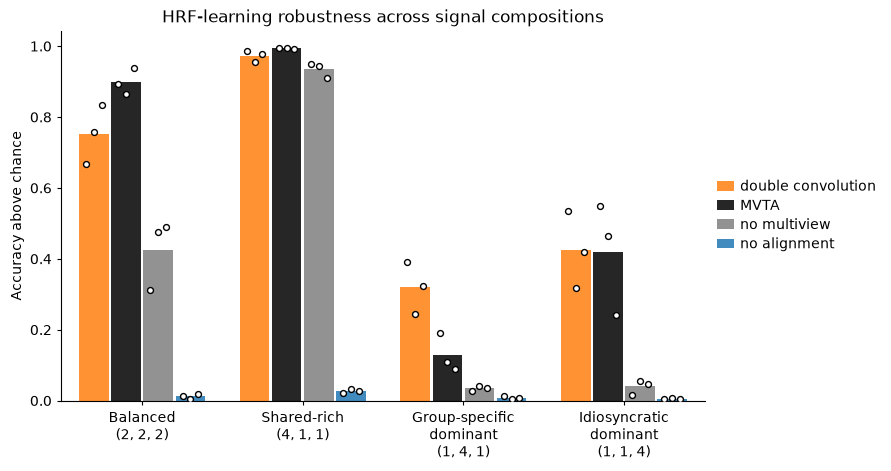

In [ ]:
fig = plot_sed_methods(
    robustness_results,
    title="HRF-learning robustness across signal compositions",
)
ax = fig.axes[0]
ax.set_xticklabels(ax.get_xticklabels(), rotation=0, ha="center")
ax.legend(
    frameon=False, ncol=1, loc="center left", bbox_to_anchor=(1.01, 0.5),
    borderaxespad=0, labelspacing=0.35, handlelength=1.2, handletextpad=0.45,
);

Note that the double-convolution approach is priviledged because it uses the same HRF used to generate the synthetic data.  learn_hrf_transform_hrf_variability.ipynb explores the impact of hemodynamic mismodeling.